# TP2 : Extraction d'information 
**Corpus :** CAMille, *Le Soir* 
**Année choisie :** 1914

## 1. Le corpus et le choix de l'année

### Imports

In [1]:
import os
from collections import defaultdict

### Lister les fichiers du corpus

In [2]:
data_path = "../../data/txt"
files = sorted([f for f in os.listdir(data_path) if f.endswith('.txt')])
len(files)

7936

### Nombre de fichiers par année

In [3]:
count_year = defaultdict(int)
for f in files:
    y = f.split("_")[2].split("-")[0]
    count_year[y] += 1
for y in sorted(count_year):
    print(y, count_year[y])

1887 36
1888 100
1889 100
1890 100
1891 100
1892 100
1893 100
1894 100
1895 100
1896 100
1897 100
1898 100
1900 100
1901 100
1902 100
1903 100
1904 100
1905 100
1906 100
1907 100
1908 100
1909 100
1910 100
1911 100
1912 100
1913 100
1914 100
1918 100
1919 100
1920 100
1921 100
1922 100
1923 100
1924 100
1925 100
1926 100
1927 100
1928 100
1929 100
1930 100
1931 100
1932 100
1933 100
1934 100
1935 100
1936 100
1937 100
1938 100
1939 100
1940 100
1941 100
1942 100
1943 100
1944 100
1945 100
1946 100
1947 100
1948 100
1949 100
1950 100
1951 100
1952 100
1953 100
1954 100
1955 100
1956 100
1957 100
1958 100
1959 100
1960 100
1961 100
1962 100
1963 100
1964 100
1965 100
1966 100
1967 100
1968 100
1969 100
1970 100


### Recherche de termes liés à l'école et à la lecture 

In [4]:
# Compter les termes dans chaque année
terms = ["dyslexi", "cécité verbale", "decroly", "scolaire", "lecture", "école",
         "enseignement", "apprentissage", "alphabétisation"]
counts = {}
for t in terms:
    counts[t] = defaultdict(int)
for f in files:
    y = f.split("_")[2].split("-")[0]
    text = open(os.path.join(data_path, f), 'r', encoding='utf-8').read().lower()
    for t in terms:
        counts[t][y] += text.count(t)

In [5]:
# Trier et imprimer les cinq années principales pour chaque terme
for t in terms:
    sorted_years = sorted(counts[t].items(), key=lambda kv: kv[1], reverse=True)
    total = sum(counts[t].values())
    print(f"{t} : {total} au total | années principales : {sorted_years[:5]}")

dyslexi : 8 au total | années principales : [('1966', 8), ('1887', 0), ('1888', 0), ('1889', 0), ('1890', 0)]
cécité verbale : 0 au total | années principales : [('1887', 0), ('1888', 0), ('1889', 0), ('1890', 0), ('1891', 0)]
decroly : 27 au total | années principales : [('1950', 9), ('1893', 2), ('1945', 2), ('1946', 2), ('1954', 2)]
scolaire : 2749 au total | années principales : [('1935', 87), ('1952', 86), ('1936', 85), ('1964', 82), ('1934', 81)]
lecture : 2149 au total | années principales : [('1946', 57), ('1892', 54), ('1905', 54), ('1932', 50), ('1906', 47)]
école : 6675 au total | années principales : [('1914', 195), ('1906', 127), ('1908', 127), ('1956', 127), ('1957', 127)]
enseignement : 12934 au total | années principales : [('1946', 266), ('1933', 248), ('1931', 239), ('1921', 238), ('1940', 238)]
apprentissage : 398 au total | années principales : [('1919', 16), ('1943', 16), ('1923', 15), ('1924', 14), ('1953', 14)]
alphabétisation : 0 au total | années principales : 

### Choisir une année

In [6]:
year = 1914

# Fichiers de cette année
files_year = [f for f in files if f.split("_")[2].split("-")[0] == str(year)]
len(files_year)

100

In [7]:
# Premier et dernier fichier de l'année (01/1914 à 08/1914)
print(files_year[0])
print(files_year[-1])

KB_JB838_1914-01-01_01-00004.txt
KB_JB838_1914-08-20_01-00004.txt


In [8]:
# Vérification pour 1914 : mentions de la loi scolaire et de la guerre
for t in ["poullet", "loi scolaire", "instruction obligatoire", "enseignement primaire", "question scolaire", "guerre"]:
    n = 0
    for f in files_year:
        text = open(os.path.join(data_path, f), 'r', encoding='utf-8').read().lower()
        n += text.count(t)
    print(f"{t} : {n}")

poullet : 12
loi scolaire : 20
instruction obligatoire : 3
enseignement primaire : 4
question scolaire : 1
guerre : 197


## 2. Extraction de mots-clés (YAKE)

### Imports

In [9]:
import yake
from collections import Counter

### Instancier l'extracteur de mots-clés

In [10]:
kw_extractor = yake.KeywordExtractor(lan="fr", top=50)
kw_extractor

### Extraire les mots-clés de tous les documents de l'année

In [11]:
for f in files_year:
    text = open(os.path.join(data_path, f), 'r', encoding="utf-8").read()
    keywords = kw_extractor.extract_keywords(text)
    kept = []
    for kw, score in keywords:
        words = kw.split()
        if len(words) == 2:
            kept.append(kw)
    print(f"{f} mentions these keywords: {', '.join(kept)}...")

KB_JB838_1914-01-01_01-00004.txt mentions these keywords: Fragson venait, plus grande, plus fie, plus meurtrière, rte plus...
KB_JB838_1914-01-02_01-00007.txt mentions these keywords: Agence Rossel, demande JEUNE, dem. fem, l’Agence Rossel, SERVEUSE Rue, ETRENNES UTILES, rue Jourdan, DEMANDE bon, RUE NEUVE, traitement Initial, Agence Rossai, demande faire...
KB_JB838_1914-01-10_01-00004.txt mentions these keywords: JANVIH Caleris, Congo paris, VENTE PUBLIQUE, Congo Belge, Froment blanc...
KB_JB838_1914-01-14_01-00008.txt mentions these keywords: Envol franco, Menthe Gripekoven, Charbon Gripekoven, dentifrice Rhelngold, chaux granulé, CHAUX GRIPEKOVEN, QUINQUINA GRIPEKOVEN, GRIPEKOVEN C’est, maux d’estomac, GRANULES GRIPEKOVEN, lithine granulée...
KB_JB838_1914-01-15_01-00002.txt mentions these keywords: loi scolaire, centime additionnel, Parlement belge, maison Krupp, instituteurs libres, Seconde Chambre...
KB_JB838_1914-01-16_01-00003.txt mentions these keywords: DERNIERE HEU, Mme Sar

### Mots-clés les plus fréquents sur l'ensemble de l'année

In [12]:
# Mots-clés (bigrammes) les plus fréquents sur l'ensemble de l'année
all_keywords = Counter()
for f in files_year:
    text = open(os.path.join(data_path, f), 'r', encoding='utf-8').read()
    keywords = kw_extractor.extract_keywords(text)
    for kw, score in keywords:
        if len(kw.split()) == 2:
            all_keywords[kw.lower()] += 1
all_keywords.most_common(30)

[('agence rossel', 27),
 ('rue royale', 17),
 ('rue van', 15),
 ('rue neuve', 13),
 ('eau tombée', 8),
 ('belle maison', 7),
 ('prix modéré', 7),
 ('louer bel', 7),
 ('jeune fille', 7),
 ('dem. fem', 6),
 ('bon état', 6),
 ('bas prix', 6),
 ('jne fille', 6),
 ('tne fille', 6),
 ('dem. serv', 6),
 ('pari mutuel', 6),
 ('louer maison', 6),
 ('hier soir', 5),
 ('notaire van', 5),
 ('bon piano', 5),
 ('loi scolaire', 4),
 ('fille dés.', 4),
 ('louer rue', 4),
 ('prix mod', 4),
 ('dem. bon', 4),
 ('bons gages', 4),
 ('demande fille', 4),
 ('louer vaste', 4),
 ('demande jeune', 3),
 ('demande bon', 3)]

In [28]:
# Quelques mots-clés thématiques
for kw in ["loi scolaire", "écoles libres", "question scolaire", "l’armée belge", "troupes allemandes", "enseignement primaire", "instruction obligatoire", "enseignement secondaire"]:
    print(kw, all_keywords[kw])

loi scolaire 4
écoles libres 2
question scolaire 1
l’armée belge 2
troupes allemandes 1
enseignement primaire 0
instruction obligatoire 0
enseignement secondaire 0


### Répartition du mot « guerre » dans l'année

Le mot "guerre" n'apparait pas parmi les mots-clés, car on ne garde que les bigrammes. On compte donc ses occurrences page par page.

In [14]:
# Compter le nombre de "guerre" dans chaque page de l'année
guerre_par_page = defaultdict(int)
for f in files_year:
    text = open(os.path.join(data_path, f), 'r', encoding='utf-8').read().lower()
    guerre_par_page[f] = text.count("guerre")

In [15]:
# Trier et imprimer les 10 pages qui en contiennent le plus
sorted_pages = sorted(guerre_par_page.items(), key=lambda kv: kv[1], reverse=True)

for page, freq in sorted_pages[:10]:
    print(f"{page} contient {freq} fois le mot 'guerre'")

KB_JB838_1914-08-15_01-00003.txt contient 26 fois le mot 'guerre'
KB_JB838_1914-08-09_01-00001.txt contient 20 fois le mot 'guerre'
KB_JB838_1914-07-10_01-00003.txt contient 15 fois le mot 'guerre'
KB_JB838_1914-08-09_01-00002.txt contient 13 fois le mot 'guerre'
KB_JB838_1914-05-22_01-00002.txt contient 12 fois le mot 'guerre'
KB_JB838_1914-06-24_01-00002.txt contient 11 fois le mot 'guerre'
KB_JB838_1914-03-16_01-00003.txt contient 9 fois le mot 'guerre'
KB_JB838_1914-07-01_01-00002.txt contient 8 fois le mot 'guerre'
KB_JB838_1914-01-15_01-00002.txt contient 7 fois le mot 'guerre'
KB_JB838_1914-06-22_01-00001.txt contient 7 fois le mot 'guerre'


## 3. Nuage de mots

### Imports

In [16]:
from wordcloud import WordCloud
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image
from unidecode import unidecode

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Mirei\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


### Stopwords (enrichis de manière itérative)
À partir de la liste de NLTK et des mots ajoutés dans le notebook du cours, la liste a été enrichie en sept itérations, en observant à chaque fois les 50 termes les plus fréquents : abréviations des petites annonces et erreurs d'OCR, vocabulaire des annonces, expressions de temps, puis résidus. La liste de NLTK s'étant révélée incomplète (absence de « elles », « quand », « ceux »...), on y a ajouté celle de spaCy à la dernière itération. Le nettoyage s'arrête lorsque les mots restants relèvent du contenu, même général, afin de ne pas orienter le résultat.

In [17]:
# Stopwords
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem"]

#Itération 1 : abréviations des petites annonces, erreurs d'OCR et mots grammaticaux
sw += ["dés", "ecr", "adr", "mod", "fem", "cuis", "etc", "jne", "tne", "ruo", "très", "toute", "peu", "chez", "près"]

# Itération 2 : vocabulaire des petites annonces (immobilier, emploi, ventes) 
sw += ["rue", "prix", "maison", "louer", "demande", "vend", "vendre", "vente", "agence", "avenue", "francs", "notaire", "fille", "gaz", "eau", "cour", "salle", "quart", "bel", "belle", "bon", "bonne", "bons", "grand", "grande"]

# Itération 3 : expressions de temps (mois, jours, heures) 
sw += ["ans", "heures", "mois", "jours", "jour", "soir", "matin", "temps", "hier", "janvier", "février", "mars", "avril", "mai", "juin", "juillet", "août", "lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"] 
# Itération 3 (suite) : abréviations et erreurs d'OCR restantes, mots grammaticaux 
sw += ["brux", "sal", "jard", "sér", "app", "pet", "com", "cap", "rne", "serv", "chamb", "garn", "pens", "mén", "enf", "pers", "sach", "aveo", "rien", "leurs", "vers", "avant", "suite", "part"]

# Itération 4 : derniers résidus (abréviations, mots généraux, petites annonces) 
sw += ["con", "aven", "ord", "prés", "quelques", "fois", "toujours", "seul", "cent", "demi", "appart", "chambre", "jardin", "contenant"]

# Itération 5 : résidus (OCR, abréviations, temps, petites annonces) 
sw += ["eor", "dom", "mme", "heure", "courant", "moment", "lieu", "garni", "pension", "piano", "beau", "petit", "bas"]

# Itération 6 : mots grammaticaux restants et cohérence des catégories 
# (adresses et offres d'emploi des petites annonces) 
sw += ["elles", "quand", "dès", "devant", "voir", "premier", "première", "chaussée", "boulevard", "place", "femme", "dame", "homme", "jeune"]

# Itération 7 : la liste NLTK étant incomplète, on ajoute celle de spaCy (plus complète) 
# et quelques mots grammaticaux absents des deux listes 
from spacy.lang.fr.stop_words import STOP_WORDS 
sw += list(STOP_WORDS) 
sw += ["beaucoup", "trop", "oui", "jamais"] 
# Itération 7 (suite) : derniers termes des petites annonces 
sw += ["ecrire", "écrire", "occasion", "villa", "rentier", "réf", "hom", "hommes", "petite", "gros", "tel", "tél", "cond", "refer", "réfer", "places", "franc", "franç"]

sw = set(sw)

### Créer un fichier contenant le texte de tous les journaux de l'année

In [18]:
# Stocker le contenu des fichiers de l'année dans une liste
content_list = []
for txt in files_year:
    with open(os.path.join(data_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [19]:
# Compter le nombre d'éléments dans la liste
len(content_list)

100

In [20]:
# Ecrire tout le contenu dans un fichier temporaire
temp_path = '../../data/tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

In [21]:
# Imprimer le contenu du fichier et constater les "déchets"
with open(os.path.join(temp_path, f'{year}.txt'), 'r', encoding='utf-8') as f:
    before = f.read()

before[:500]

"tin drame de famille. — Tué,pâr:riJh père, • ^. ETCHARPE&. SKUN6S VERITABLES, ' Un‘des chanteurs français, lefi -jribs pôpu-.; 4#-cfiotx, &)%’mitais'; LILIV; m~, rivale, : ïàli^;-HtfiW'‘Pottî;i)lo?}cqnniuiço^^e.ift,€nf6j.ae.: c J ‘ ■ 1 - - * . * wiaw4 litni* /ïnr\\-û Æûa -nttf/irtïT^lJl^flC .1 1 • Fragson,* est mort liier,dans des cireaitatahces y ' tragiques. Il a été tué d’un coup de revolver !* ‘par son père, un vieillard;-de': 84 fttavfi’ant .^rftge-a altéré les facultés 1 meot&lesr ‘ ' ' 1 •"

### Fonction de nettoyage (adaptée : suppression des accents)
Les majuscules de l'époque ne sont pas toujours accentuées : « ÉTAT » et « ETAT » étaient comptés comme deux mots différents. La fonction a donc été adaptée avec unidecode, qui supprime les accents après le filtrage des stopwords. Effet : « ETAT » passe à 540 occurrences et « ECOLE » entre dans les 50 termes les plus fréquents.

In [22]:
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        # Adaptation : suppression des accents pour regrouper ÉTAT et ETAT (majuscules non accentuées)
        kept = [unidecode(w).upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

In [23]:
clean_text(year, folder=temp_path)

'Output has been written in ../../data/tmp/1914_clean.txt!'

In [24]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'TIN DRAME FAMILLE TUE PAR RIJH PERE ETCHARPE VERITABLES CHANTEURS FRANCAIS LEFI JRIBS POPU CFIOTX MITAIS LILIV RIVALE IALI HTFIW POTTI CQNNIUICO IFT LITNI INR AEUA NTTF IRTIT LJL FLC FRAGSON MORT LIIER CIREAITATAHCES TRAGIQUES TUE COUP REVOLVER PERE VIEILLARD FTTAVFI ANT RFTGE ALTERE FACULTES MEOT LESR DRAME FAMILLE TFOST PRODUIT FRAGSON OECUPAITAVEC SOB DETTJ AFTPAM MENT FAYETTE PARLA VIEILLARD ETUTT IRRITABLE AUEINTD SORTE FOIIEEE NJIE PRENANT FORME DELIREDE JYQRSECD ITION FILS AMIE UALT PIE N'

### Afficher les termes les plus fréquents

In [25]:
frequencies = Counter(after.split())
print(frequencies.most_common(50))

[('BRUXELLES', 1462), ('MIDI', 611), ('NORD', 587), ('ETAT', 540), ('SAINT', 455), ('PARIS', 412), ('BELGIQUE', 337), ('PORTE', 336), ('ANVERS', 334), ('FER', 331), ('MARCHE', 327), ('BELGE', 324), ('COURS', 319), ('NEUF', 305), ('METRES', 293), ('BUREAU', 259), ('FRANCE', 257), ('MINISTRE', 257), ('TRAM', 257), ('LOI', 253), ('GOUVERNEMENT', 252), ('GARE', 248), ('GENERAL', 246), ('LIEGE', 243), ('PAYS', 243), ('COMMERCE', 238), ('PARTIE', 235), ('ORDRE', 235), ('PRESIDENT', 234), ('HOTEL', 230), ('VIE', 225), ('DONNE', 221), ('ROI', 216), ('JEAN', 215), ('SOCIETE', 214), ('VUE', 210), ('AGE', 202), ('FRANCAIS', 200), ('GUERRE', 198), ('MORT', 193), ('ECOLE', 190), ('NOM', 187), ('ART', 186), ('OUVRIER', 185), ('POINT', 185), ('CENTRE', 185), ('IXELLES', 184), ('BOURSE', 182), ('FORT', 179), ('FOND', 179)]


### Créer, stocker et afficher le nuage de mots

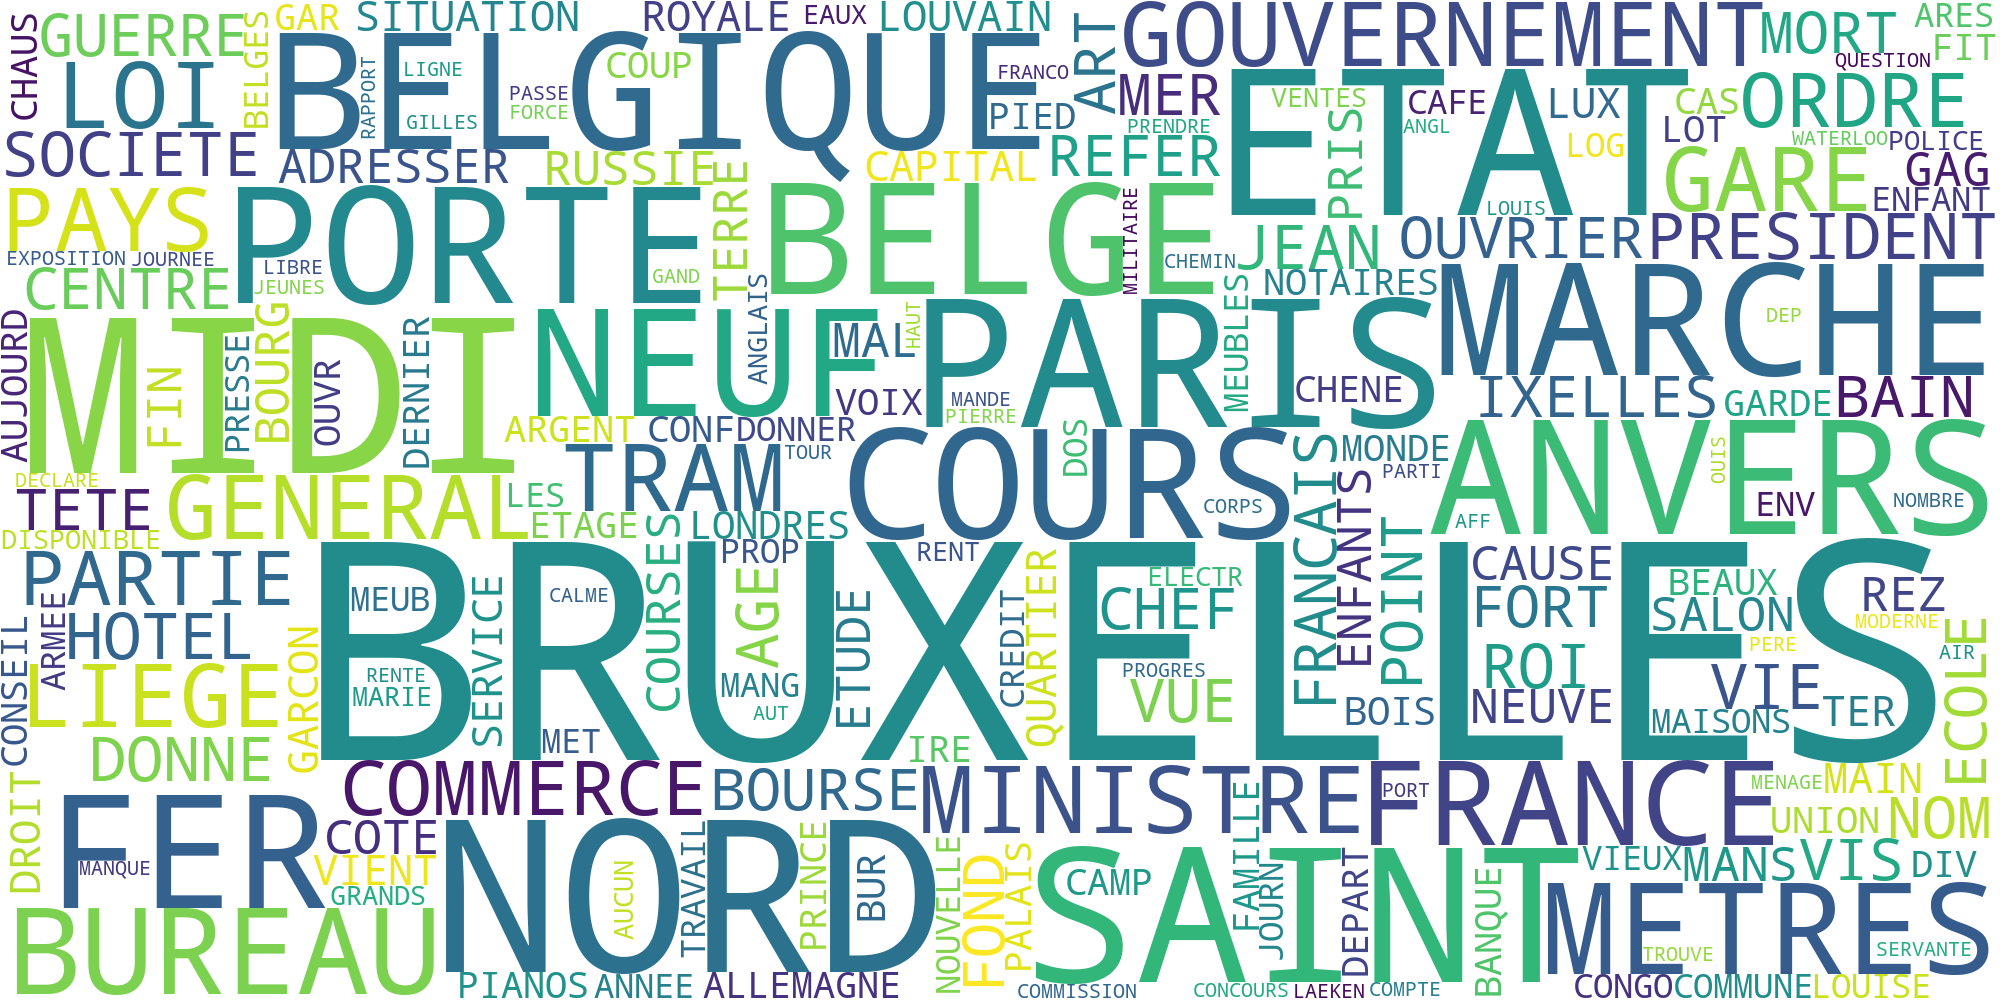

In [26]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))